# Verifiable Performance Estimation with Cliffordization
This tutorial will guide you through the principles and implementation of a benchmarking technique called **Cliffordization**. You'll learn how to estimate the performance of a generic quantum circuit by running a related, but classically simulatable, Clifford circuit. We'll explore the theory, implement the method using a robust, parameterized approach, and apply it to a practical physics simulation circuit (Ising model Trotter circuit).

## 1. Estimating Application Performance with Clifford Proxy Circuits

Benchmarking quantum processing units (QPU) is a critical but challenging task. As systems grow larger, classically simulating their output to check for correctness becomes impossible. A common solution is to benchmark using circuits made only of Clifford Gates (like CNOT, CZ, H, S) which can be efficiently simulated on a classical computer thanks to [Gottesman-Knill theorem $\nearrow$](https://arxiv.org/pdf/quant-ph/0406196).

However, a nagging question remains: do these Clifford-based benchmarks truly reflect how the processor will perform on non-Clifford circuits, which are necessary for quantum advantage? It's possible that Clifford circuits might overlook specific error sources that only become apparent when running more complex algorithm. With this in mind, this tutorial explores the finding of [Merkel et al. 2025 $\nearrow$](https://arxiv.org/pdf/2503.05943), who show that for a broad class of realistic noise models, **Clifford benchmarks are indeed sufficient**. Accordingly, we will walk through their central technique, "Cliffordization", to estimate the performance of a non-Clifford target circuit by measuring the fidelity of a much simpler "proxy" circuit.

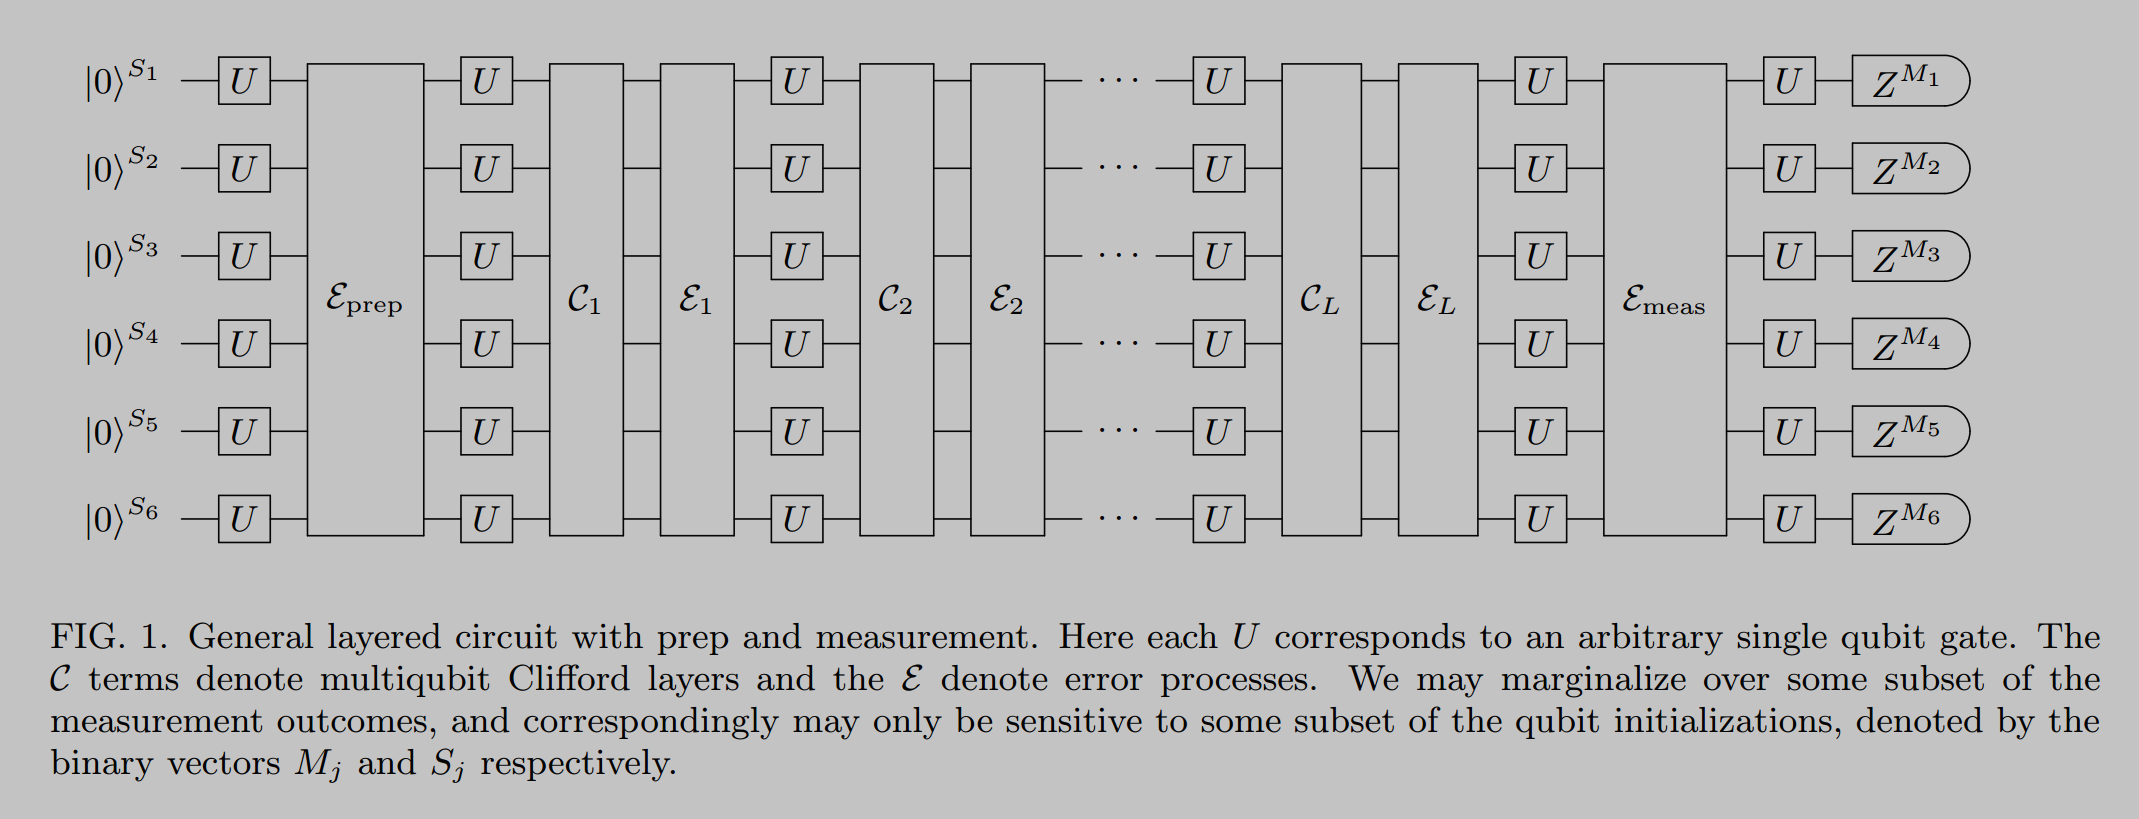

In [23]:
from IPython.display import Image
Image(filename = 'fig_layered_circ.png', width=1200, height=1200)

**What you'll learn**
1. **The Pauli twirling assumption (PTA)**: Theoretical foundation that makes their technique work.
2. **Cliffordization**: Process of generating a Clifford proxy from a generic target circuit.
3. **Parameterized circuits**: An efficient implementation strategy based on the provided [`cliffordize_utils.py` $\nearrow$](https://github.com/qiskit-community/qiskit-device-benchmarking/blob/520a9f0bff6ec93367f06bef6d6749544ef605fb/qiskit_device_benchmarking/utilities/cliffordize_utils.py).
4. **SPAM-robust fidelity estimation** A method using reference circuits to get reliable measurements.
5. **Use Case**: How to benchmark an **Ising model Trotter circuit** and compare its performance against the random circuit sampling (RCS), mirroring the experiments in the paper.

**Setup**

First, let's import the necessary libraries.

In [1]:
# General imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Qiskit imports
from qiskit import QuantumCircuit, QuantumRegister, transpile
from qiskit.circuit import Parameter
from qiskit.circuit.library import RZGate, SXGate
from qiskit.dagcircuit import DAGCircuit
from qiskit.quantum_info import Pauli, random_clifford, Clifford, Statevector, SparsePauliOp
from qiskit.primitives.containers.bindings_array import BindingsArray
from qiskit.transpiler import PassManager, TransformationPass
from qiskit.synthesis import OneQubitEulerDecomposer

from qiskit_experiments.library.randomized_benchmarking.clifford_utils import CliffordUtils

# Qiskit IBM Runtime Imports
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, SamplerV2 as Sampler

# Simulator and Noise Imports
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

# Initialize the service
# QiskitRuntimeService.save_account(token = "<your-API-token>", 
#                                   instance = "<IBM Cloud CRN or instance name>", 
#                                   overwrite=True)

## 2. The Core Concepts

**Pauli twirling assumption (PTA)** posits that a family of error models where the noise process associated with a layer of multi-qubit gates (e.g., layer of CNOTs) is _independent of the single-qubit gates_ applied immediately before or after it. This independence allows one to use a technique called [Pauli twirling $\nearrow$](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques) to average the effect of complex, coherent errors into a simpler, Pauli stochastic error channel. A Pauli stochastic channel is just a probabilistic mixture of Pauli errors (I, X, Y, Z), which is much easier to model and analyze.

**Cliffordization (creating a proxy circuit)** is the process of creating a classically simulatable "proxy" circuit, $\mathcal{C}$, from a non-Clifford target circuit, $\mathcal{U}$. To do this, we keep the multi-qubit gates the same and replace every single-qubit gate with a _randomly chosen single-qubit Clifford gate_.

The paper's key result is that under the PTA, the **diamond distance** (worst-case error) of $\mathcal{U}$ is well-approximated by the **process infidelity** (average error) of its $\mathcal{C}$:
$$
    d_\diamond (\mathcal{U}) \approx r(\mathcal{C})
$$
This means we can learn about the worst-case performance of any application circuit by simply measuring the average error of an efficiently simulatable proxy circuit.

## 3. Measuring Fidelity Robustly Against SPAM

To measure the process infidelity, $r(\mathcal{C})$, we need a protocol that is robust to the **state preparation and measurement (SPAM)** errors. [Merkel et al. 2025 $\nearrow$](https://arxiv.org/pdf/2503.05943) proposes a method using a **reference circuit** that builds on ideas from [mirror benchmarking $\nearrow$](https://arxiv.org/abs/2204.07568). The idea relies on the fact that fidelities of Pauli channels are approximately multiplicative. The procedure is as follows:
1. **Define a "scrambling" circuit $\mathcal{L}$**. This is a short, random layered Clifford circuit. Its purpose is to randomize the relationship between the input and output states for the fidelity measurement, ensuring the effect of SPAM is consistent across experiments. A circuit depth that is logarithmic in the number of qubits is both necessary and sufficient for this scrambling.
2. **Run Experiment A:** Measure the fidelity to the combined circuit $\mathcal{C}$ followed by $\mathcal{L}$, which we denote $\mathcal{L} \circ \mathcal{C}$. The measured fidelity is approximately $F_\mathcal{L} \circ \mathcal{C} \approx F_\text{SPAM} \times F_\mathcal{L} \times F_\mathcal{C}$.
3. **Run Experiment B:** Measure the fidelity of the scrambling circuit $\mathcal{L}$ by itself. The measured fidelity is $F_\mathcal{L} \approx F_\text{SPAM} \times F_\mathcal{L}$.
4. **Calculate the SPAM-free fidelity:** By dividing the two results, the contributions from SPAM and the scrambler cancel out, isolating the fidelity of our proxy circuit $\mathcal{C}$.
$$
    F_\mathcal{C} \approx \frac{F_{\mathcal{L} \circ \mathcal{C}}}{F_\mathcal{L}}
$$
This provides a SPAM-robust estimate of the fidelity we want. Note that this method requires a slightly stronger assumption than the PTA alone: namely, that the SPAM and scrambler errors are the same whether the main proxy circuit $\mathcal{C}$ or not.

## 4. An Efficient Implementation with Parameterized Circuits

Instead of generating many distinct `QuantumCircuit` object for each randomization, we will use a more efficient approach inspired by the `SingleDecompass` and `Cliffordize` classes in the provided [`cliffordize_utils.py`$\nearrow$](https://github.com/qiskit-community/qiskit-device-benchmarking/blob/520a9f0bff6ec93367f06bef6d6749544ef605fb/qiskit_device_benchmarking/utilities/cliffordize_utils.py). We create a single **parameterized template circuit** and use Qiskit's `BindingsArray` module to run all randomizations in a single, efficient job.

### Step 1: Create a parameterized template circuit

We define a `TransformationPass` that finds every single-qubit gate and replaces it with a parameterized block of gates, $R_Z(\theta_0) S_X R_Z(\theta_1) S_X R_Z(\theta_2)$. This `ZSX` decomposition can represent any single-qubit unitary.

In [2]:
class SingleDecompPass(TransformationPass):
    """
    Replace every single-qubit gate by a parameterised Z-SX-Z-SX-Z block.
    Time order of the block: RZ(z_0), SX, RZ(z_1), SX, RZ(z_2).
    Parameters are named ``l_{layer}_q_{qubit}_z_{k}``; the layer index increases at
    every barrier. Multi-qubit gates are left untouched.
    """

    def run(self, dag: DAGCircuit) -> DAGCircuit:
        layer_idx = 1
        for node in dag.op_nodes(include_directives=True):
            if node.op.name == "barrier":
                layer_idx += 1
                continue
            if node.op.num_qubits == 1:
                q = dag.find_bit(node.qargs[0]).index
                z = [Parameter(f"l_{layer_idx}_q_{q}_z_{k}") for k in range(3)]
                rep = DAGCircuit()
                qreg = QuantumRegister(1)
                rep.add_qreg(qreg)
                for gate in (RZGate(z[0]), SXGate(), RZGate(z[1]), SXGate(), RZGate(z[2])):
                    rep.apply_operation_back(gate, qargs=(qreg[0],))
                dag.substitute_node_with_dag(node=node, input_dag=rep)
        return dag

### Step 2: Generate bindings for Cliffordization

We now pre-calculate the angle parameters for all $24$ single-qubit Clifford gates. To "Cliffordize" our template, we just need to randomly select from these pre-calculated parameter sets and build a `BindingsArray`.

In [3]:
_DECOMPOSER = OneQubitEulerDecomposer(basis="ZSX")


def zsx_block_angles(unitary):
    """Angles [z_0, z_1, z_2] such that RZ(z_0) SX RZ(z_1) SX RZ(z_2) (time order)
    equals ``unitary`` up to a global phase.

    ``OneQubitEulerDecomposer.angles`` returns ZYZ Euler angles (theta, phi, lam), i.e.
    U = Rz(phi) Ry(theta) Rz(lam); the Z-SX-Z-SX-Z block needs the pi shifts below.
    """
    theta, phi, lam = _DECOMPOSER.angles(unitary)
    return [lam, theta + np.pi, phi + np.pi]


# Angles for all 24 single-qubit Clifford gates (modulo global phase)
SINGLE_QUBIT_CLIFFORD_ANGLES = [
    zsx_block_angles(CliffordUtils.clifford_1_qubit(i).to_matrix()) for i in range(24)
]


def get_clifford_bindings(template_circuit, num_samples):
    """List of parameter dictionaries for random Cliffordizations of ``template_circuit``."""
    num_layers = 0
    if template_circuit.parameters:
        num_layers = max(int(str(p).split("_")[1]) for p in template_circuit.parameters) + 1
    clifford_choices = np.random.randint(24, size=(num_samples, num_layers, template_circuit.num_qubits))
    all_bindings = []
    for s in range(num_samples):
        sample = {}
        for param in template_circuit.parameters:
            _, layer, _, qubit, _, k = str(param).split("_")
            idx = clifford_choices[s, int(layer), int(qubit)]
            sample[param] = SINGLE_QUBIT_CLIFFORD_ANGLES[idx][int(k)]
        all_bindings.append(sample)
    return all_bindings


# --- Sanity check: verify each stored angle set reproduces its Clifford ---
from qiskit.quantum_info import Operator

for i in range(24):
    θ0, θ1, θ2 = SINGLE_QUBIT_CLIFFORD_ANGLES[i]
    qc = QuantumCircuit(1)
    qc.rz(θ0, 0)
    qc.sx(0)
    qc.rz(θ1, 0)
    qc.sx(0)
    qc.rz(θ2, 0)

    target = CliffordUtils.clifford_1_qubit(i).to_matrix()
    U = Operator(qc).data

    # Compare up to global phase using the largest-magnitude entry as reference
    idx = np.unravel_index(np.argmax(np.abs(target)), target.shape)
    phase = U[idx] / target[idx]
    assert np.allclose(U, phase * target, atol=1e-8), f"Mismatch for Clifford {i}"

print("All 24 Clifford angle sets verified ✓")

All 24 Clifford angle sets verified ✓


## 5. Use Case: Benchmarking an Ising Model Trotter Circuit

Let's apply this technique to a structure circuit from an actual algorithm: [a Trotter step from a transverse field Ising model simulation $\nearrow$](https://quantum.cloud.ibm.com/docs/en/tutorials/probabilistic-error-amplification). This provides a more realistic test of the benchmark's predictive power. This experiments mirrors the comparison to [random circuit sampling (RCS) $\nearrow$](https://nguyenquantum.github.io/Random_circuit_sampling.pdf) performed in Section V-D of the paper. Its figure of merit is the [linear cross-entropy (XE) $\nearrow$](https://arxiv.org/pdf/2007.07872), defined as:
$$
    \textit{XE}_{(p_\text{exp}, p_\text{ideal})} = \frac{2^n \sum_i p_\text{exp}(i) p_\text{ideal}(i) - 1}{2^n \sum_j p_\text{ideal}(j)^2 - 1}
$$
where $p_\text{exp}$ and $p_\text{ideal}$ are the experimental and ideal output probability distributions.

### Step 1. Generate Haar bindings for RCS and calculate linear XE

Haar bindings, which derive from the Haar measure, account for 'uniform sampling' and thus utilized in RCS which we employ them for the linear XE estimation.

In [4]:
def get_haar_bindings(template_circuit, num_samples):
    """List of parameter dictionaries drawing every single-qubit gate Haar-randomly."""
    params = list(template_circuit.parameters)
    all_bindings = []
    for _ in range(num_samples):
        # one Haar-random gate per (layer, qubit), shared by its three angles
        gate_angles = {}
        sample = {}
        for p in params:
            _, layer, _, qubit, _, k = str(p).split("_")
            key = (layer, qubit)
            if key not in gate_angles:
                u = np.random.uniform(0, 1)
                theta = 2 * np.arccos(np.sqrt(u))   # cos(theta) uniform on [-1, 1]
                phi = np.random.uniform(0, 2 * np.pi)
                lam = np.random.uniform(0, 2 * np.pi)
                gate_angles[key] = [lam, theta + np.pi, phi + np.pi]
            sample[p] = gate_angles[key][int(k)]
        all_bindings.append(sample)
    return all_bindings

# --- Calculate Linear Cross-Entropy ---
def linear_xeb(exp_counts, ideal_probs, num_qubits):
    """Calculate linear cross-entropy."""
    p_exp = {int(k, 2): v for k, v in exp_counts.items()}
    p_ideal = {int(k, 2): v for k, v in ideal_probs.items()}

    # XE(p_exp, p_ideal) Eq. 11 in paper
    overlap = sum(p_exp.get(k, 0) * p for k, p in p_ideal.items())
    p_ideal_norm_sq = sum(p**2 for p in p_ideal.values())
    return (2**num_qubits * overlap - 1) / (2**num_qubits * p_ideal_norm_sq - 1)

### Step 2: Define the Ising model circuit

We create a function to generate a circuit for the Hamiltonian $H = - \sum_{ij} J_{ij} Z_i Z_j - \sum_i h_i X_i$. For this tutorial, we will use a simple 1D chain with uniform parameters. The single-qubit gates are placeholders that our `SingleDecompPass` will convert into parameterized gates.

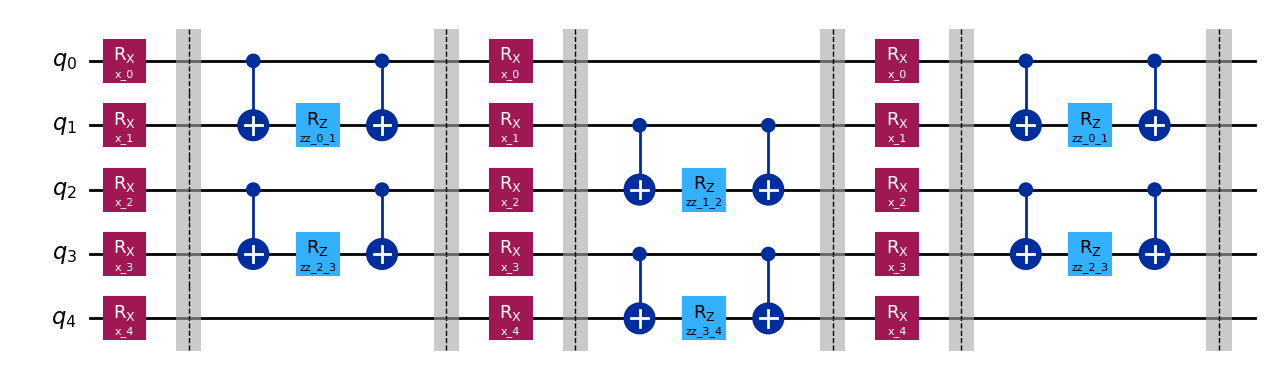

In [5]:
def ising_trotter_circuit(num_qubits: int, num_steps: int, repeat_same=True) -> QuantumCircuit:
    """Creates a Trotter Ising model simulation circuit with placeholder gates."""
    # Trotter step defines time evolution of the circuit, with RZ and RX gates
    # Gate labels:  single-qubit gate -> x_step_qubit  
    #               two-qubit gate -> zz_step_1st-qubit_2nd-qubit
    qc = QuantumCircuit(num_qubits)

    # Define "one" set of parameters for reuse
    if repeat_same:
        # Time evolution under X terms
        param_x = [Parameter(f"x_{i}") for i in range(num_qubits)]
        # Time evolution under ZZ terms (decomposed to CX-RZ-CX)
        # Or use circuit.append(rzz(theta_zz), [i, i+1]) 
        param_zz = [Parameter(f"zz_{i}_{i+1}") for i in range(num_qubits - 1)]

    for step in range(num_steps):
        # If not repeating, make unique per step
        if not repeat_same:
            param_x = [Parameter(f"x_{step}_{i}") for i in range(num_qubits)]
            param_zz = [Parameter(f"zz_{step}_{i}_{i+1}") for i in range(num_qubits - 1)]
        
        for i in range(num_qubits):
            qc.rx(param_x[i], i)
        qc.barrier()

        # Bricklayer-style entangling pattern
        if step % 2 == 0:
            # Even step: (0,1), (2,3), (4,5)
            start = 0
        else:
            # Odd step: (1,2), (3,4), (5,6)
            start = 1
        
        for i in range(start, num_qubits - 1, 2):
            qc.cx(i, i+1)
            qc.rz(param_zz[i], i+1)
            qc.cx(i, i+1)
        qc.barrier()
    return qc

# Create our target circuit and its parameterized template
num_qubits = 5
trotter_steps = 3       # num_steps
target_ising_circuit = ising_trotter_circuit(num_qubits, trotter_steps, repeat_same=True)

# Draw the target circuit
target_ising_circuit.draw("mpl", fold=-1)

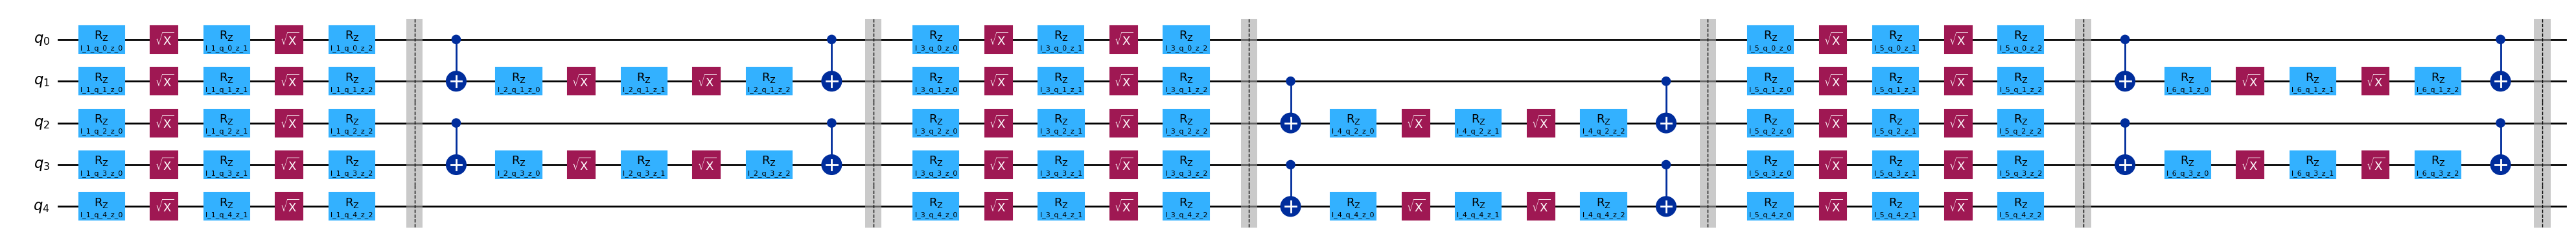

In [6]:
# Build a PassManager with SingleDecompPass
pm = PassManager([SingleDecompPass()])

# Run PassManager on the target Ising Trotter circuit
ising_template = pm.run(target_ising_circuit)

# Draw the Cliffordized Ising Trotter circuit
ising_template.draw("mpl", fold=-1)

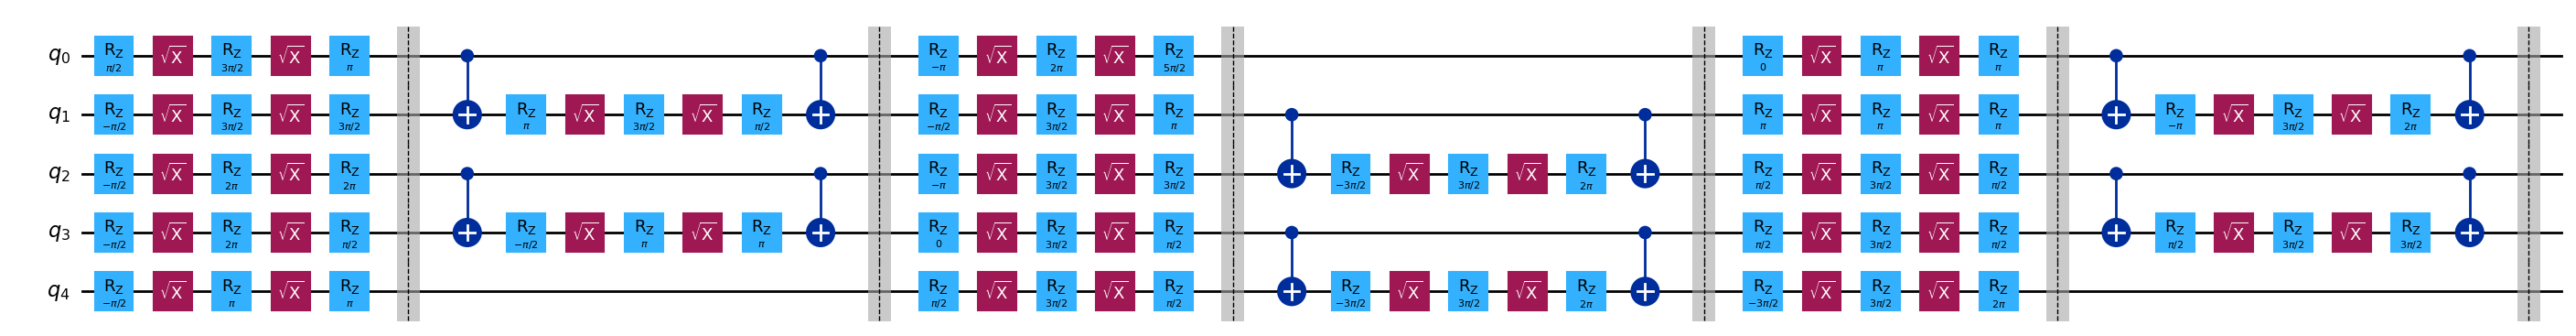

In [7]:
clifford_bindings = get_clifford_bindings(ising_template, num_samples=1)
param_binding = clifford_bindings[0]
ising_concrete = ising_template.assign_parameters(param_binding)
ising_concrete.draw("mpl", fold=-1)

In [8]:
print(type(param_binding))

<class 'dict'>


### Step 3: Compare Cliffordization fidelity with XE from RCS

Following the paper, we compare two SPAM-sensitive metrics:
1. **Cliffordization fidelity**: The **unmitigated** fidelity of Cliffordized proxy circuits.
2. **XE from RCS**: The **XE** of the Ising circuit where the evolution angles are randomized (making it a Haar-random circuit).

Strong agreement between these values shows that the simple Clifford benchmark accurately predicts the performance of the more complex, application-style circuit.

**Running the experiments across multiple depths**

* **To run the Cliffordization experiment (SPAM-sensitive)**: We use [direct fidelity estimation (DFE)$\nearrow$](https://arxiv.org/abs/1104.4695) to measure the process fidelity. For a fair comparison with XE from RCS, we will not use the SPAM-mitigation technique above where scrambling circuit introduced. However, we will utilize the protocol involves preparing a random Pauli eigenstate, running the circuit, and measuring the corresponding output Pauli called "backward propagation" by the help of function down below:

In [ ]:
def canonical_pauli_label(pauli: Pauli, num_qubits: int) -> str:
    """Pauli label without sign/phase prefix (rightmost character = qubit 0)."""
    lab = pauli.to_label()
    while lab and lab[0] in "+-i":
        lab = lab[1:]
    return lab.upper().replace(" ", "").rjust(num_qubits, "I")[-num_qubits:]


def pauli_phase_sign(pauli: Pauli) -> int:
    """+1 or -1 global sign of a Pauli; raises for +-i phases."""
    phase = pauli.phase % 4
    if phase == 0:
        return +1
    if phase == 2:
        return -1
    raise ValueError(f"Pauli has non-real phase: {pauli}")


def prepare_pauli_plus1(pauli: Pauli, num_qubits: int) -> QuantumCircuit:
    """Circuit preparing the +1 eigenstate of the *unsigned* Pauli string of ``pauli``."""
    label = canonical_pauli_label(pauli, num_qubits)
    prep = QuantumCircuit(num_qubits)
    for q in range(num_qubits):
        ch = label[num_qubits - 1 - q]          # label is little-endian
        if ch == "X":
            prep.h(q)
        elif ch == "Y":
            prep.h(q)
            prep.s(q)                           # H then S gives |+i>, the +1 eigenstate of Y
    return prep


def random_pauli(num_qubits: int) -> Pauli:
    return Pauli("".join(np.random.choice(["I", "X", "Y", "Z"], size=num_qubits)))


def sparsepauli_evolve(sp: SparsePauliOp, clifford) -> SparsePauliOp:
    """Heisenberg-evolve every term of ``sp``: P -> C^dag P C."""
    terms = []
    for p, coeff in zip(sp.paulis, sp.coeffs):
        terms.append((p.evolve(clifford).to_label(), coeff))
    return SparsePauliOp.from_list(terms)


def dfe_input_pauli(output_pauli: Pauli, clifford: Clifford) -> Pauli:
    """P_in such that C P_in C^dag = P_out, i.e. P_in = C^dag P_out C (Heisenberg picture)."""
    return output_pauli.evolve(clifford)


# Extract first Pauli from a SparsePauliOp
def get_first_label(sp: SparsePauliOp) -> str:
    """Extract the first Pauli label from a SparsePauliOp."""
    try:
        return sp.to_labels()[0]
    except AttributeError:
        return sp.paulis[0].to_label()

* **To run the XE-RCS experiment**: We generate random (Haar-random) rotations, run the `Sampler`, and compare the measured distribution to the ideal one to get the linear cross-entropy.

We will loop through a set of depths, and for each of these depths perform both the Cliffordization and XE-RCS experiments. As a reference we will first consider the ideal case where no noise present:

In [10]:
# --- Simulator Choice ---
# service = QiskitRuntimeService()
# For real hardware:
# backend_real = service.least_busy(operational=True, simulator=False, min_num_qubits=127)

# For local simulation
backend_sim = AerSimulator(shots=10000)


# --- Experiment Parameters ---
num_qubits = 5
depths = [4, 8, 12, 16, 20, 24, 28]     # corresponds to number of Trotter steps
num_samples = 500                       # number of randomizations per depth point

# --- Data storage ---
results = {"num_entanglers": [], "cliff_fidelity": [], "rcs_xeb": []}

# --- Main Experimental Loop ---
for depth in depths:
    print(f"Running depth = {depth} for {num_qubits} qubits...")

    # 1. Create and parameterize the circuit
    target_circuit = ising_trotter_circuit(num_qubits, depth)
    num_entanglers = target_circuit.count_ops().get('cx', 0)
    results['num_entanglers'].append(num_entanglers)

    pm = PassManager([SingleDecompPass()])
    template = pm.run(target_circuit)
    clifford_bindings = get_clifford_bindings(template, num_samples)
    haar_bindings_list = get_haar_bindings(template, num_samples)
    param_map = {p: np.array([sample[p] for sample in haar_bindings_list]) for p in template.parameters}
    haar_bindings = BindingsArray(param_map)

    # --- 2. Cliffordization Experiment (DFE) ---
    # Set up DFE observables and state preparation
    # For each sample, we pick a random output Pauli to measure.
    # We then classically calculate the corresponding input Pauli.
    # Finally, we add gates to prepare a +1 eigenstate of that input Pauli.

    signs = []
    cliff_pubs = []
    for i in range(num_samples):
        # Choose a random output Pauli
        output_pauli = Pauli("".join(np.random.choice(['I', 'X', 'Y', 'Z'], size=num_qubits)))

        # Create the ideal Clifford circuit for this sample to find the input state
        param_dict = clifford_bindings[i]
        ideal_circuit = template.assign_parameters(param_dict)
        C = Clifford(ideal_circuit)

        # The input Pauli is P_in = C_ideal^dag * P_out * C_ideal
        input_pauli = dfe_input_pauli(output_pauli, C)  # P_in = C^dag P_out C (Heisenberg picture)
        signs.append(pauli_phase_sign(input_pauli))  # sign of the propagated Pauli

        # Create a state preparation circuit for a +1 eigenstate of P_in
        prep_circuit = prepare_pauli_plus1(input_pauli, num_qubits)
        
        # Combine prep circuit with the main template
        full_circuit_template = prep_circuit.compose(template)

        # Add measurements so Estimator/Sampler can use this
        # meas_circuit = full_circuit_template.copy()
        # meas_circuit.measure_all()
        
        cliff_pubs.append((full_circuit_template, output_pauli, clifford_bindings[i]))
   
    # Run with Estimator
    estimator = Estimator(mode=backend_sim)
    job_cliff = estimator.run(pubs=cliff_pubs)
    cliff_result = job_cliff.result()
    evs = np.array([float(np.squeeze(pub.data.evs)) for pub in cliff_result])
    # DFE: the prepared state is the +1 eigenstate of the unsigned P_in, so <P_out> = sign ideally
    cliff_fidelity = np.mean(np.array(signs) * evs)
    cliff_infidelity = 1 - cliff_fidelity

    results["cliff_fidelity"].append(cliff_fidelity)
    # print(f"  -> Clifford Infidelity: {cliff_infidelity:.4f}")
    print(f"  -> Clifford Fidelity: {cliff_fidelity:.4f}")

    # --- 3. XE-RCS Experiment ---
    # Run with Sampler
    sampler = Sampler(mode=backend_sim)
    rcs_probs_list = []
    for param_dict in haar_bindings_list:
        # Add measurement to all qubits in the template
        meas_circuit = template.copy()
        meas_circuit.measure_all()

        job_rcs = sampler.run(pubs=[(meas_circuit, param_dict)])
        rcs_result = job_rcs.result()
        counts = rcs_result[0].data.meas.get_counts()
        total_counts = sum(counts.values())
        
        exp_probs = {bitstring: count / total_counts for bitstring, count in counts.items()}
        rcs_probs_list.append(exp_probs)

    print(f"Collected {len(rcs_probs_list)} quasi-distributions (expected {num_samples})")

    # Classical post processing for XEB
    avg_xeb = 0.0
    for i, exp_counts in enumerate(rcs_probs_list):
        bound_circuit = template.assign_parameters(haar_bindings_list[i])

        ideal_probs = Statevector(bound_circuit).probabilities_dict(qargs=list(range(num_qubits)))
        avg_xeb += linear_xeb(exp_counts, ideal_probs, num_qubits)
        
    avg_xeb /= len(rcs_probs_list)
    results["rcs_xeb"].append(avg_xeb)
    print(f"  -> XEB from RCS: {avg_xeb:.4f}\n")

Running depth = 4 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 500 quasi-distributions (expected 500)
  -> XEB from RCS: 1.0000

Running depth = 8 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 500 quasi-distributions (expected 500)
  -> XEB from RCS: 0.9983

Running depth = 12 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 500 quasi-distributions (expected 500)
  -> XEB from RCS: 0.9979

Running depth = 16 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 500 quasi-distributions (expected 500)
  -> XEB from RCS: 1.0011

Running depth = 20 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 500 quasi-distributions (expected 500)
  -> XEB from RCS: 0.9988

Running depth = 24 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 500 quasi-distributions (expected 500)
  -> XEB from RCS: 1.0044

Running depth = 28 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 500 quasi-distributions (expected 500)
  -> XEB from RCS: 1.0009



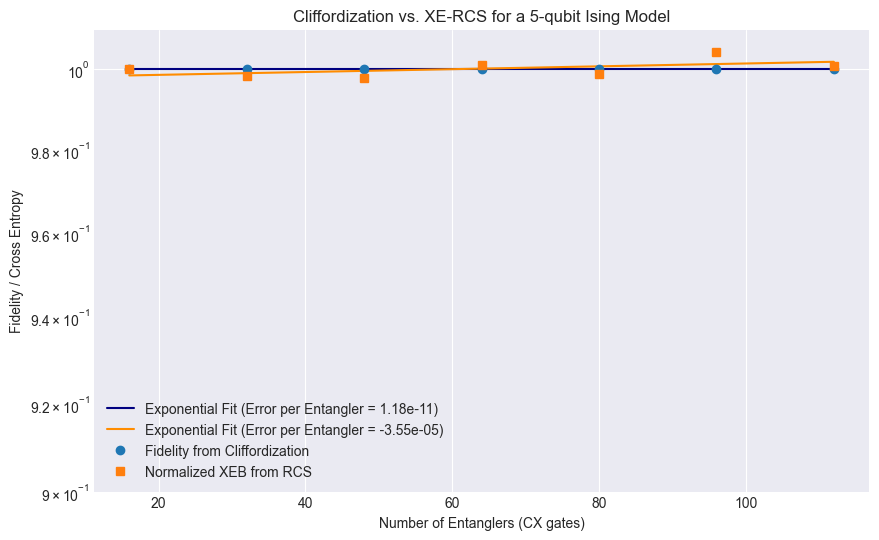

In [11]:
# --- Plotting ---
plt.style.use("seaborn-v0_8-darkgrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Results
x_data = np.array(results["num_entanglers"])
y_fid = np.array(results["cliff_fidelity"])
y_rcs = np.array(results["rcs_xeb"])

# Plot Cliffordization Fidelity
ax.errorbar(x_data, y_fid, fmt='o', capsize=5, label='Fidelity from Cliffordization')

# Plot RCS XEB
ax.errorbar(x_data, y_rcs, fmt='s', capsize=5, label='Normalized XEB from RCS')

# Exponential Fit
def exp_decay(x, a, b):
    return a * np.exp(-b * x)
fit_x = np.linspace(min(x_data), max(x_data), 200)

# Clifford Fidelity fit
popt_fid, _ = curve_fit(exp_decay, x_data, y_fid, p0=(1, 0.01))
fit_y_fid = exp_decay(fit_x, * popt_fid)
ax.plot(fit_x, fit_y_fid, '-', color='navy', label=f'Exponential Fit (Error per Entangler = {popt_fid[1]:.2e})')

# RCS XEB fit_x
popt_rcs, _ = curve_fit(exp_decay, x_data, y_rcs, p0=(1, 0.01))
fit_y_rcs = exp_decay(fit_x, * popt_rcs)
ax.plot(fit_x, fit_y_rcs, '-', color='darkorange', label=f'Exponential Fit (Error per Entangler = {popt_rcs[1]:.2e})')

# Formatting
ax.set_yscale('log')
ax.set_ylim(0.9, 1.01)
ax.set_xlabel('Number of Entanglers (CX gates)')
ax.set_ylabel('Fidelity / Cross Entropy')
ax.set_title(f'Cliffordization vs. XE-RCS for a {num_qubits}-qubit Ising Model')
ax.legend()
plt.show()

In [14]:
# --- Experiment Parameters for multiple qubit_sizes ---
qubit_sizes = [5, 10, 15]
depths_dict = {nq: [2, 4, 6, 8, 10, 12, 14] for nq in qubit_sizes}
num_samples = 100                    # number of randomizations per depth point

# --- Data storage ---
results = {nq: {"num_entanglers": [], "cliff_fidelity": [], "rcs_xeb": []} for nq in qubit_sizes}

# --- Main Experimental Loop ---
for num_qubits in qubit_sizes:
    depths = depths_dict[num_qubits]
    print(f"\n=== Running experiments for {num_qubits} qubits ===")
    
    for depth in depths:
        print(f"Running depth = {depth} for {num_qubits} qubits...")

        # 1. Create and parameterize the circuit
        target_circuit = ising_trotter_circuit(num_qubits, depth)
        num_entanglers = target_circuit.count_ops().get('cx', 0)
        results[num_qubits]['num_entanglers'].append(num_entanglers)

        pm = PassManager([SingleDecompPass()])
        template = pm.run(target_circuit)
        clifford_bindings = get_clifford_bindings(template, num_samples)
        haar_bindings_list = get_haar_bindings(template, num_samples)
        param_map = {p: np.array([sample[p] for sample in haar_bindings_list]) for p in template.parameters}
        haar_bindings = BindingsArray(param_map)

        # --- 2. Cliffordization Experiment (DFE) ---
        # Set up DFE observables and state preparation
        # For each sample, we pick a random output Pauli to measure.
        # We then classically calculate the corresponding input Pauli.
        # Finally, we add gates to prepare a +1 eigenstate of that input Pauli.

        signs = []
        cliff_pubs = []
        for i in range(num_samples):
            # Choose a random output Pauli
            output_pauli = Pauli("".join(np.random.choice(['I', 'X', 'Y', 'Z'], size=num_qubits)))

            # Create the ideal Clifford circuit for this sample to find the input state
            param_dict = clifford_bindings[i]
            ideal_circuit = template.assign_parameters(param_dict)
            C = Clifford(ideal_circuit)

            # The input Pauli is P_in = C_ideal^dag * P_out * C_ideal
            input_pauli = dfe_input_pauli(output_pauli, C)  # P_in = C^dag P_out C (Heisenberg picture)
            signs.append(pauli_phase_sign(input_pauli))  # sign of the propagated Pauli

            # Create a state preparation circuit for a +1 eigenstate of P_in
            prep_circuit = prepare_pauli_plus1(input_pauli, num_qubits)
            
            # Combine prep circuit with the main template
            full_circuit_template = prep_circuit.compose(template)
            # print(full_circuit_template.count_ops())
            
            cliff_pubs.append((full_circuit_template, output_pauli, clifford_bindings[i]))
    
        # Run with Estimator
        estimator = Estimator(mode=backend_sim)
        job_cliff = estimator.run(pubs=cliff_pubs)
        cliff_result = job_cliff.result()
        evs = np.array([float(np.squeeze(pub.data.evs)) for pub in cliff_result])
        # DFE: the prepared state is the +1 eigenstate of the unsigned P_in, so <P_out> = sign ideally
        cliff_fidelity = np.mean(np.array(signs) * evs)
        cliff_infidelity = 1 - cliff_fidelity

        results[num_qubits]["cliff_fidelity"].append(cliff_fidelity)
        # print(f"  -> Clifford Infidelity: {cliff_infidelity:.4f}")
        print(f"  -> Clifford Fidelity: {cliff_fidelity:.4f}")

        # --- 3. XE-RCS Experiment ---
        # Run with Sampler
        sampler = Sampler(mode=backend_sim)
        rcs_probs_list = []
        for param_dict in haar_bindings_list:
            # Add measurement to all qubits in the template
            meas_circuit = template.copy()
            meas_circuit.measure_all()

            job_rcs = sampler.run(pubs=[(meas_circuit, param_dict)])
            rcs_result = job_rcs.result()
            counts = rcs_result[0].data.meas.get_counts()
            total_counts = sum(counts.values())
            
            exp_probs = {bitstring: count / total_counts for bitstring, count in counts.items()}
            rcs_probs_list.append(exp_probs)

        print(f"Collected {len(rcs_probs_list)} quasi-distributions (expected {num_samples})")

        # Classical post processing for XEB
        avg_xeb = 0.0
        for i, exp_counts in enumerate(rcs_probs_list):
            bound_circuit = template.assign_parameters(haar_bindings_list[i])

            ideal_probs = Statevector(bound_circuit).probabilities_dict(qargs=list(range(num_qubits)))
            avg_xeb += linear_xeb(exp_counts, ideal_probs, num_qubits)
            
        avg_xeb /= len(rcs_probs_list)
        results[num_qubits]["rcs_xeb"].append(avg_xeb)
        print(f"  -> XEB from RCS: {avg_xeb:.4f}\n")


=== Running experiments for 5 qubits ===
Running depth = 2 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 100 quasi-distributions (expected 100)
  -> XEB from RCS: 0.9977

Running depth = 4 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 100 quasi-distributions (expected 100)
  -> XEB from RCS: 1.0013

Running depth = 6 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 100 quasi-distributions (expected 100)
  -> XEB from RCS: 1.0008

Running depth = 8 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 100 quasi-distributions (expected 100)
  -> XEB from RCS: 1.0052

Running depth = 10 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 100 quasi-distributions (expected 100)
  -> XEB from RCS: 1.0013

Running depth = 12 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 100 quasi-distributions (expected 100)
  -> XEB from RCS: 1.0014

Running depth = 14 for 5 qubits...
  -> Clifford Fidelity: 1.0000
Collected 100 quasi-distributions (expected 

C:\Users\tan\AppData\Local\Temp\ipykernel_13228\1878010419.py:23: RuntimeWarning: overflow encountered in exp
  return a * np.exp(-b * x)


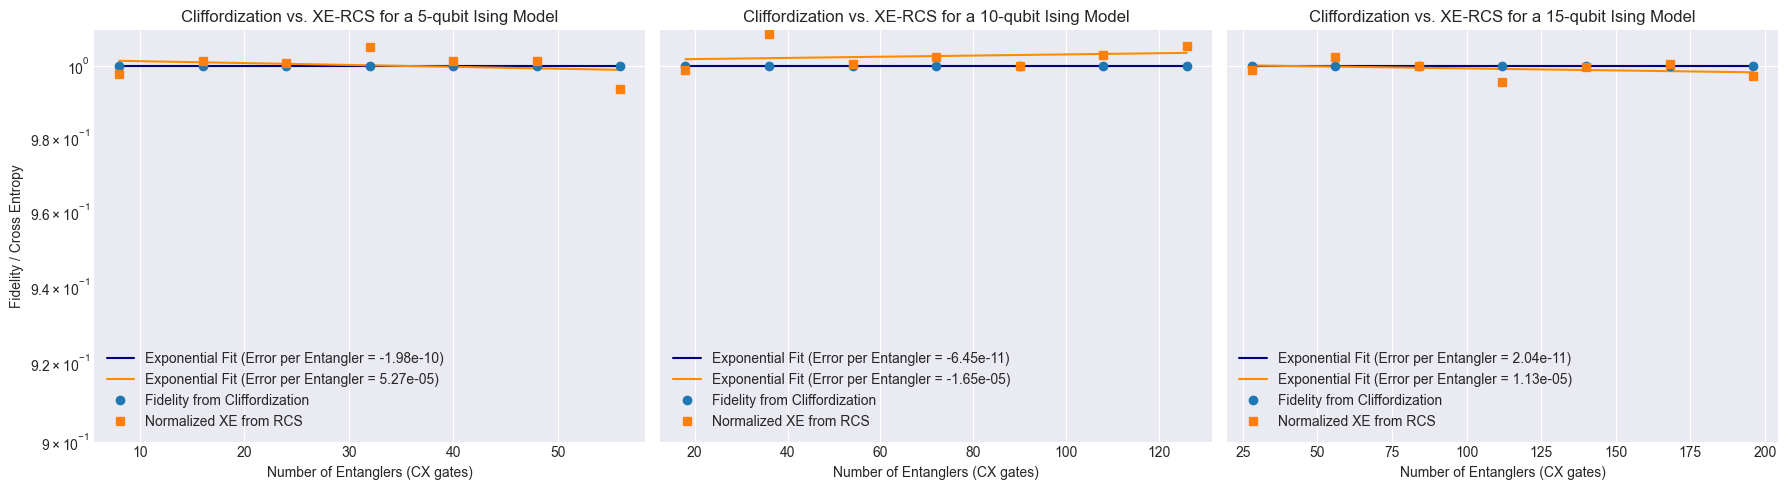

In [15]:
# --- Plotting multiple qubit sizes ---
plt.style.use("seaborn-v0_8-darkgrid")

num_qubit_sizes = len(qubit_sizes)
fig, axes = plt.subplots(1, num_qubit_sizes, figsize=(6*num_qubit_sizes, 5), sharey=True)

if num_qubit_sizes == 1:
    axes = [axes] # ensure iterable

for ax, nq in zip(axes, qubit_sizes):
    x_data = np.array(results[nq]["num_entanglers"])
    y_fid = np.array(results[nq]["cliff_fidelity"])
    y_rcs = np.array(results[nq]["rcs_xeb"])

    # Plot Cliffordization Fidelity
    ax.errorbar(x_data, y_fid, fmt='o', capsize=5, label='Fidelity from Cliffordization')

    # Plot XE-RCS
    ax.errorbar(x_data, y_rcs, fmt='s', capsize=5, label='Normalized XE from RCS')

    # Exponential Fit
    def exp_decay(x, a, b):
        return a * np.exp(-b * x)
    fit_x = np.linspace(min(x_data), max(x_data), 200)

    # Clifford Fidelity fit
    try:
        popt_fid, _ = curve_fit(exp_decay, x_data, y_fid, p0=(1, 0.1))
        fit_y_fid = exp_decay(fit_x, * popt_fid)
        ax.plot(fit_x, fit_y_fid, '-', color='navy', label=f'Exponential Fit (Error per Entangler = {popt_fid[1]:.2e})')
    except:
        pass # in case curve_fit fails

    # XE-RCS fit_x
    try:
        popt_rcs, _ = curve_fit(exp_decay, x_data, y_rcs, p0=(1, 0.1))
        fit_y_rcs = exp_decay(fit_x, * popt_rcs)
        ax.plot(fit_x, fit_y_rcs, '-', color='darkorange', label=f'Exponential Fit (Error per Entangler = {popt_rcs[1]:.2e})')
    except:
        pass

    # Formatting
    ax.set_yscale('log')
    ax.set_ylim(0.9, 1.01)
    ax.set_xlabel('Number of Entanglers (CX gates)')
    ax.set_title(f'Cliffordization vs. XE-RCS for a {nq}-qubit Ising Model')
    ax.legend()

axes[0].set_ylabel('Fidelity / Cross Entropy')
plt.tight_layout()
plt.show()

Now, we will consider the same setup with noise by the error values introduced to each gate:

In [16]:
# Adding Noise
noise_model = NoiseModel()
single_qubit_error = depolarizing_error(0.0001, 1)
noise_model.add_all_qubit_quantum_error(single_qubit_error, ["rz", "rx", "sx", "id"])

two_qubit_error = depolarizing_error(0.002, 2)
noise_model.add_all_qubit_quantum_error(two_qubit_error, ["cx"])

noisy_basis = noise_model.basis_gates

# For local simulation
backend_sim = AerSimulator(
    noise_model=noise_model,
    basis_gates=noise_model.basis_gates,
    shots=1024
)

# --- Experiment Parameters for multiple qubit_sizes ---
qubit_sizes = [5, 10, 15]
depths_dict = {nq: [2, 4, 6, 8, 10, 12, 14] for nq in qubit_sizes}    # corresponds to number of Trotter steps
num_samples = 10                    # number of randomizations per depth point

# --- Data storage ---
results = {nq: {"num_entanglers": [], "cliff_fidelity": [], "rcs_xeb": []} for nq in qubit_sizes}

# --- Main Experimental Loop ---
for num_qubits in qubit_sizes:
    depths = depths_dict[num_qubits]
    print(f"\n=== Running experiments for {num_qubits} qubits ===")

    for depth in depths:
        print(f"Running depth = {depth} for {num_qubits} qubits...")

        # 1. Create and parameterize the circuit
        target_circuit = ising_trotter_circuit(num_qubits, depth)
        num_entanglers = target_circuit.count_ops().get('cx', 0)
        results[num_qubits]['num_entanglers'].append(num_entanglers)

        pm = PassManager([SingleDecompPass()])
        template = pm.run(target_circuit)
        clifford_bindings = get_clifford_bindings(template, num_samples)
        haar_bindings_list = get_haar_bindings(template, num_samples)
        param_map = {p: np.array([sample[p] for sample in haar_bindings_list]) for p in template.parameters}
        haar_bindings = BindingsArray(param_map)

        # --- 2. Cliffordization Experiment (DFE) ---
        # Set up DFE observables and state preparation
        # For each sample, we pick a random output Pauli to measure.
        # We then classically calculate the corresponding input Pauli.
        # Finally, we add gates to prepare a +1 eigenstate of that input Pauli.

        signs = []
        cliff_pubs = []
        for i in range(num_samples):
            # Choose a random output Pauli
            output_pauli = Pauli("".join(np.random.choice(['I', 'X', 'Y', 'Z'], size=num_qubits)))

            # Create the ideal Clifford circuit for this sample to find the input state
            param_dict = clifford_bindings[i]
            ideal_circuit = template.assign_parameters(param_dict)
            C = Clifford(ideal_circuit)

            # The input Pauli is P_in = C_ideal^dag * P_out * C_ideal
            input_pauli = dfe_input_pauli(output_pauli, C)  # P_in = C^dag P_out C (Heisenberg picture)
            signs.append(pauli_phase_sign(input_pauli))  # sign of the propagated Pauli

            # Create a state preparation circuit for a +1 eigenstate of P_in
            prep_circuit = prepare_pauli_plus1(input_pauli, num_qubits)
            
            # Combine prep circuit with the main template
            full_circuit_template = prep_circuit.compose(template)

            # Transpile full circuit template
            transpiled_circuit = transpile(
                full_circuit_template,
                basis_gates=noisy_basis,
                optimization_level=0
            )

            # Diagnostic:
            if i == 0:
                print("--- Verifying Circuit Gates ---")
                print("Ops BEFORE transpilation:", full_circuit_template.count_ops()) 

            if i == 0:
                print("Ops AFTER transpilation:", transpiled_circuit.count_ops())
                print("-----------------------------")

            cliff_pubs.append((transpiled_circuit, output_pauli, clifford_bindings[i]))
    
        # Run with Estimator
        estimator = Estimator(mode=backend_sim)
        job_cliff = estimator.run(pubs=cliff_pubs)
        cliff_result = job_cliff.result()
        evs = np.array([float(np.squeeze(pub.data.evs)) for pub in cliff_result])
        # DFE: the prepared state is the +1 eigenstate of the unsigned P_in, so <P_out> = sign ideally
        cliff_fidelity = np.mean(np.array(signs) * evs)
        cliff_infidelity = 1 - cliff_fidelity

        results[num_qubits]["cliff_fidelity"].append(cliff_fidelity)
        print(f"  -> Clifford Fidelity: {cliff_fidelity:.4f}")

        # --- 3. XE-RCS Experiment ---
        # Run with Sampler
        sampler = Sampler(mode=backend_sim)
        rcs_probs_list = []
        for param_dict in haar_bindings_list:
            # Add measurement to all qubits in the template
            meas_circuit = template.copy()
            meas_circuit.measure_all()

            job_rcs = sampler.run(pubs=[(meas_circuit, param_dict)])
            rcs_result = job_rcs.result()
            counts = rcs_result[0].data.meas.get_counts()
            total_counts = sum(counts.values())
            
            exp_probs = {bitstring: count / total_counts for bitstring, count in counts.items()}
            rcs_probs_list.append(exp_probs)

        print(f"Collected {len(rcs_probs_list)} quasi-distributions (expected {num_samples})")

        # Classical post processing for XEB
        avg_xeb = 0.0
        for i, exp_counts in enumerate(rcs_probs_list):
            bound_circuit = template.assign_parameters(haar_bindings_list[i])

            ideal_probs = Statevector(bound_circuit).probabilities_dict(qargs=list(range(num_qubits)))
            avg_xeb += linear_xeb(exp_counts, ideal_probs, num_qubits)
            
        avg_xeb /= len(rcs_probs_list)
        results[num_qubits]["rcs_xeb"].append(avg_xeb)
        print(f"  -> XEB from RCS: {avg_xeb:.4f}\n")


=== Running experiments for 5 qubits ===
Running depth = 2 for 5 qubits...
--- Verifying Circuit Gates ---
Ops BEFORE transpilation: OrderedDict({'rz': 42, 'sx': 28, 'cx': 8, 'barrier': 4, 'h': 2, 's': 1})
Ops AFTER transpilation: OrderedDict({'rz': 47, 'sx': 28, 'cx': 8, 'barrier': 4, 'rx': 2})
-----------------------------
  -> Clifford Fidelity: 0.9799
Collected 10 quasi-distributions (expected 10)
  -> XEB from RCS: 0.9762

Running depth = 4 for 5 qubits...
--- Verifying Circuit Gates ---
Ops BEFORE transpilation: OrderedDict({'rz': 84, 'sx': 56, 'cx': 16, 'barrier': 8, 'h': 2, 's': 1})
Ops AFTER transpilation: OrderedDict({'rz': 89, 'sx': 56, 'cx': 16, 'barrier': 8, 'rx': 2})
-----------------------------
  -> Clifford Fidelity: 0.9571
Collected 10 quasi-distributions (expected 10)
  -> XEB from RCS: 0.9623

Running depth = 6 for 5 qubits...
--- Verifying Circuit Gates ---
Ops BEFORE transpilation: OrderedDict({'rz': 126, 'sx': 84, 'cx': 24, 'barrier': 12, 'h': 3, 's': 1})
Ops AF

C:\Users\tan\AppData\Local\Temp\ipykernel_13228\3499251760.py:23: RuntimeWarning: overflow encountered in exp
  return a * np.exp(-b * x)


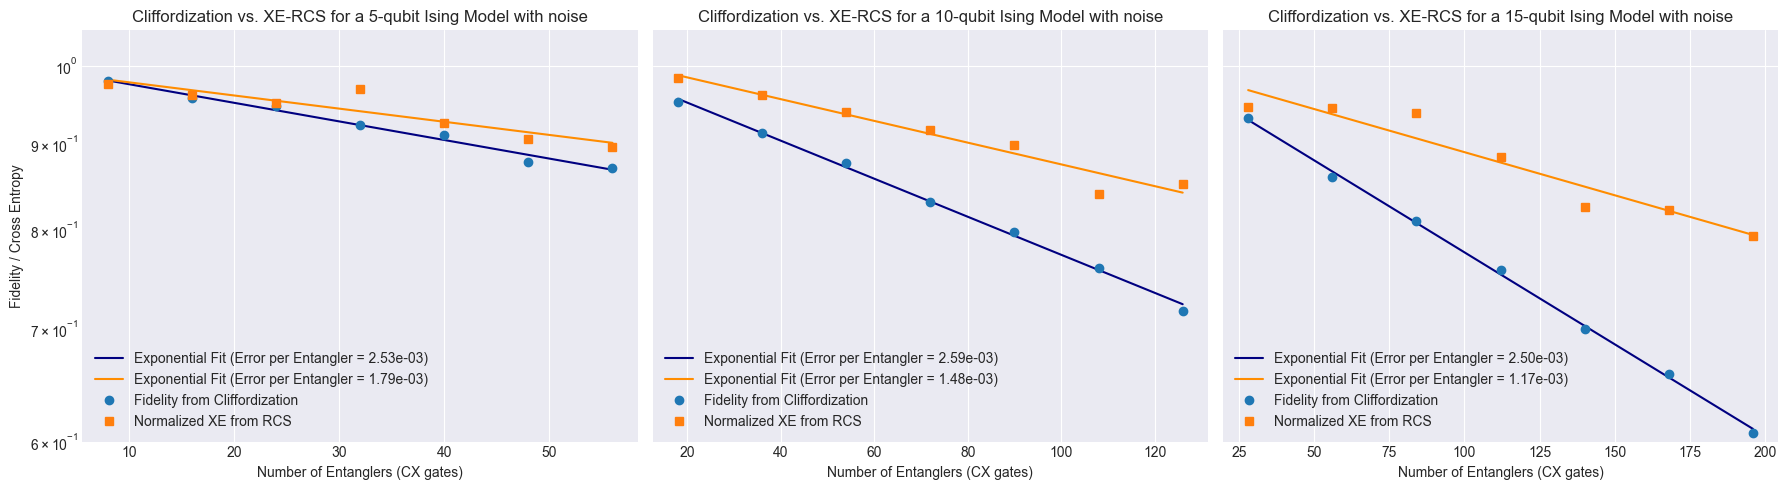

In [17]:
# --- Plotting multiple qubit sizes ---
plt.style.use("seaborn-v0_8-darkgrid")

num_qubit_sizes = len(qubit_sizes)
fig, axes = plt.subplots(1, num_qubit_sizes, figsize=(6*num_qubit_sizes, 5), sharey=True)

if num_qubit_sizes == 1:
    axes = [axes] # ensure iterable

for ax, nq in zip(axes, qubit_sizes):
    x_data = np.array(results[nq]["num_entanglers"])
    y_fid = np.array(results[nq]["cliff_fidelity"])
    y_rcs = np.array(results[nq]["rcs_xeb"])

    # Plot Cliffordization Fidelity
    ax.errorbar(x_data, y_fid, fmt='o', capsize=5, label='Fidelity from Cliffordization')

    # Plot XE-RCS
    ax.errorbar(x_data, y_rcs, fmt='s', capsize=5, label='Normalized XE from RCS')

    # Exponential Fit
    def exp_decay(x, a, b):
        return a * np.exp(-b * x)
    fit_x = np.linspace(min(x_data), max(x_data), 200)

    # Clifford Fidelity fit
    try:
        popt_fid, _ = curve_fit(exp_decay, x_data, y_fid, p0=(1, 0.1))
        fit_y_fid = exp_decay(fit_x, * popt_fid)
        ax.plot(fit_x, fit_y_fid, '-', color='navy', label=f'Exponential Fit (Error per Entangler = {popt_fid[1]:.2e})')
    except:
        pass # in case curve_fit fails

    # XE-RCS fit_x
    try:
        popt_rcs, _ = curve_fit(exp_decay, x_data, y_rcs, p0=(1, 0.1))
        fit_y_rcs = exp_decay(fit_x, * popt_rcs)
        ax.plot(fit_x, fit_y_rcs, '-', color='darkorange', label=f'Exponential Fit (Error per Entangler = {popt_rcs[1]:.2e})')
    except:
        pass

    # Formatting
    ax.set_yscale('log')
    ax.set_ylim(0.6, 1.05)
    ax.set_xlabel('Number of Entanglers (CX gates)')
    ax.set_title(f'Cliffordization vs. XE-RCS for a {nq}-qubit Ising Model with noise')
    ax.legend()

axes[0].set_ylabel('Fidelity / Cross Entropy')
plt.tight_layout()
plt.show()

### Step 4. Results $\&$ Analysis

In the ideal case, both methods; _Fidelity from Cliffordization_ and _Normalized cross-entropy (XE) from RCS_ give values very close to $1$ for the Trotter circuit of 1D Ising model (see the first set of subplots for $5, 10$ and $15$ qubits). This is expected, since no noise was added to the gates, so the circuit's layer fidelity stayed constant.

Next, we added `depolarizing_error` (the noise) to each gate (as done in [Merkel et al. (2025)](https://arxiv.org/pdf/2503.05943)). As the number of qubits and the entangling gates (CX gates) increases - which also increases the circuit depth (or number of Trotter steps) - both the fidelity estimate and cross-entropy show a clear exponential decay, as seen in the second set of subplots.

Overall, out results follow the same trend reported by Merkel et al. (see Fig. $9$ of their paper (given down below)), where both benchmarking methods agree with the layer fidelity estimates measured on IBM Heron devices. This agreement supports the idea behind the **PTA**: Cliffordized proxy circuits capture the same noise behaviour as their non-Clifford originals, making them a practical and scalable tool for estimating circuit fidelity on real hardware.

**Figure:**

Comparison of _Fidelity from Cliffordization_ and _Normalized cross-entropy (XE) from RCS_ for Trotter circuits of 1D Ising model.
* The first set of subplots ($5, 10$ and $15$ qubits) shows results for the **ideal case** with no noise, where both metrics remain close to $1$.
* The second set shows results under **depolarizing error**, where both metrics exhibit a similar exponential decay as the number of qubits and entanglers increase, consistend with the trends reported by Merkel et al..

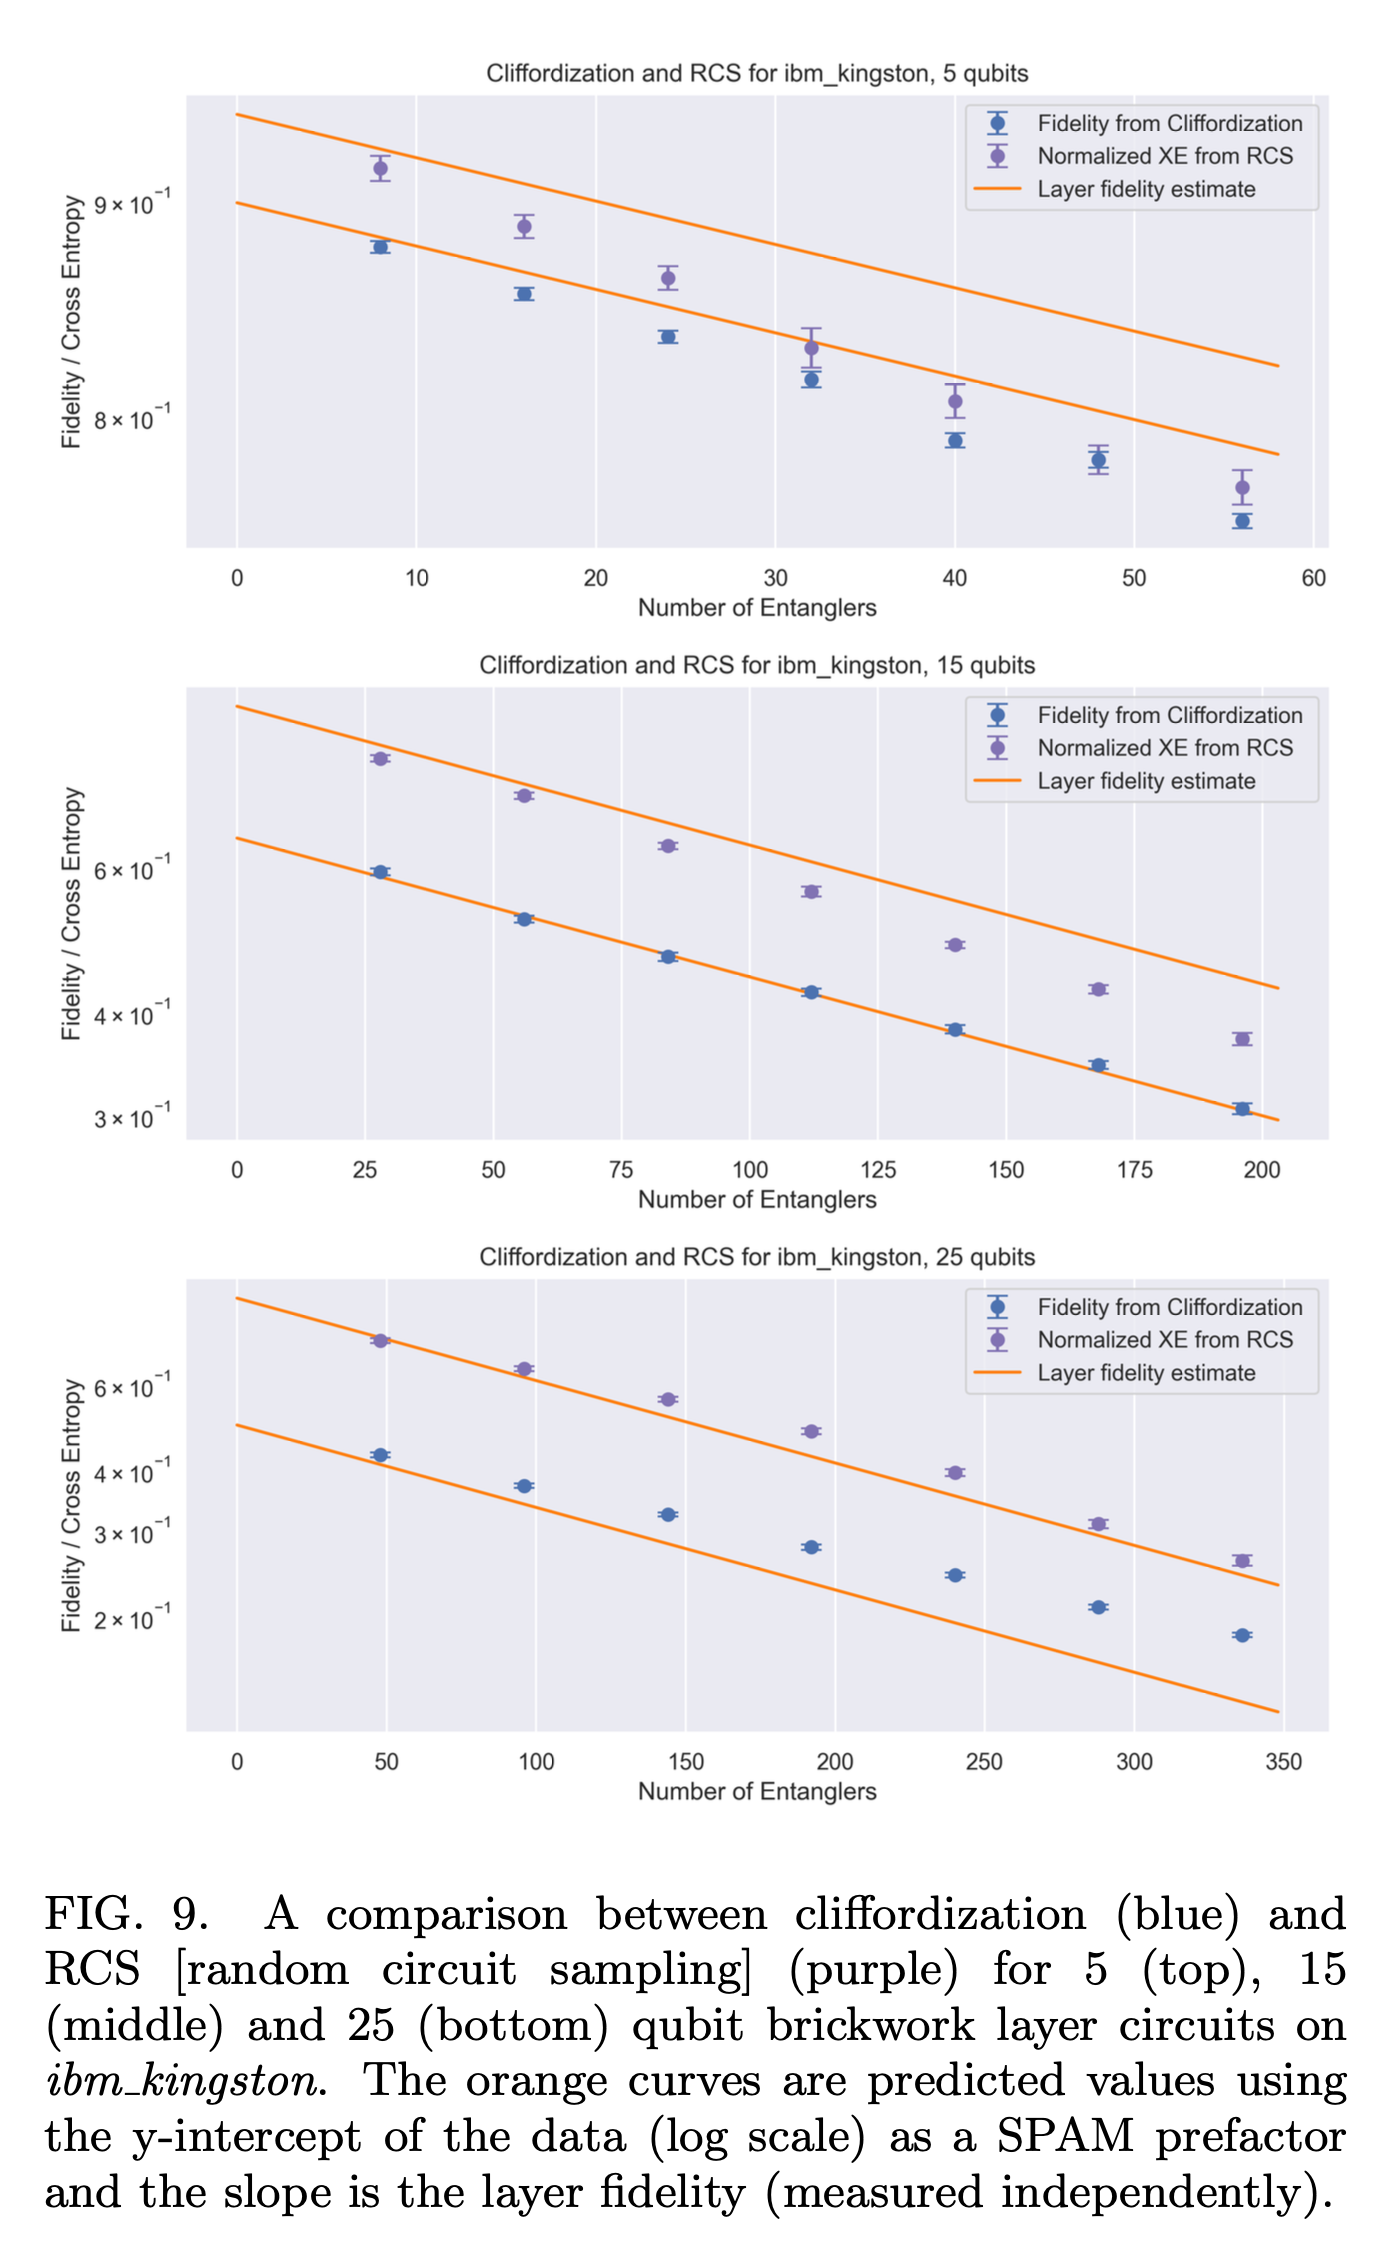

In [ ]:
from IPython.display import Image
Image(filename = "fig_merkel.png", width=600, height=600)

## 6. Conclusion

This tutorial demonstrated the benchmarking framework of [Merkel et al. 2025](https://arxiv.org/pdf/2503.05943) based on the **Pauli twirling assumption (PTA)** and **Cliffordization**, showing how generic noisy circuits can be approximated by classically tractable Pauli-stochastic models. Using **Cliffordized Trotter circuits of the 1D Ising model**, we observed consistent behaviour between **fidelity estimates from Cliffordization** and **normalized cross-entropy (XE) from randomized circuit sampling (RCS)** in agreement with the result reported by Merkel et al.. These finding confirm practical value of PTA-based proxy circuits for scalable circuit fidelity estimation and intuitively suggest future extensions like using **Clifford twirling** for global depolarizing noise mitigation and **non-Markovian noise modelling** for more realistic system characterisation.

## 7. Possible Research Topics

1. [Fractional gates $\nearrow$](https://quantum.cloud.ibm.com/docs/en/tutorials/fractional-gates), even though briefly issued in the provided repository; [`device_rb_w_lf.ipynb` $\nearrow$](https://github.com/qiskit-community/qiskit-device-benchmarking/blob/520a9f0bff6ec93367f06bef6d6749544ef605fb/notebooks/device_rb_w_lf.ipynb), they are not fully covered in the paper. And we think that, a research project addressing their role on error models premises an interesting direction by these reasons:
    * Due to their ability of direct execution of arbitrary-angle rotations they present extra efficiency in comparison to traditional gates. 
    * Their decomposition into single and two-qubit gates can introduce more accurate results in the calculations.
    * They can be used for achieving a more sensitive protocol through the consideration of partial Pauli twirling method.
2. As a possible continuation of Merkel et al.'s framework, one could consider the recently proposed [Clifford twirling method $\nearrow$](https://arxiv.org/pdf/2405.07720). While Merkel et al. show that under the PTA, Cliffordization renders noise Pauli-stochastic and thus classically tractable, Clifford twirling goes further by scrambling Pauli-stochastic noise into **global depolarizing noise** (global white noise), which enables simpler and more cost-effective error mitigation strategies.
3. Lastly, since the work of Merkel et al. relies on a **Markovian error model** to address the idealised settings, a natural future direction is to study **non-Markovian noise** as a more realistic counterpart. Such models capture temporal correlations in the noise, for example when errors are not independent across layers, or when crosstalk introduces memory effects between qubits-features that are commonly observed in real hardware but not accounted for in Markovian assumptions.